In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing import image

In [3]:
base_dir = '/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/fire_dataset'
train_dir = os.path.join(base_dir, 'Train')
val_dir = os.path.join(base_dir, 'Vali')

In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [5]:
fire_dir = os.path.join(train_dir, 'Fire')
fire_imgs = os.listdir(fire_dir)
fire_df = pd.DataFrame({
    'filename': [os.path.join('Fire', fname) for fname in fire_imgs],
    'class': 'fire'
})

no_fire_dir = os.path.join(train_dir, 'Non-Fire')
no_fire_imgs = os.listdir(no_fire_dir)
no_fire_df = pd.DataFrame({
    'filename': [os.path.join('Non-Fire', fname) for fname in no_fire_imgs],
    'class': 'Non-fire'
})

# 데이터프레임 병합
train_df = pd.concat([fire_df, no_fire_df], ignore_index=True)

# 클래스 라벨 매핑
class_map = {'fire': 1, 'Non-fire': 0}

# 데이터 생성기 설정
train_datagen = ImageDataGenerator(
    rescale=1./255,
    zoom_range=0.3,
    brightness_range=(0.6, 1.4),
    horizontal_flip=True,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1
)

# flow_from_dataframe 사용
train_data = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_dir,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

Found 6003 validated image filenames belonging to 2 classes.


In [6]:
# Fire 이미지 리스트 생성
val_fire_dir = os.path.join(val_dir, 'Fire')
val_fire_imgs = os.listdir(val_fire_dir)
val_fire_df = pd.DataFrame({
    'filename': [os.path.join('Fire', fname) for fname in val_fire_imgs],
    'class': 'fire'
})

# Non-Fire 이미지 리스트 생성
val_nonfire_dir = os.path.join(val_dir, 'Non-Fire')
val_nonfire_imgs = os.listdir(val_nonfire_dir)
val_nonfire_df = pd.DataFrame({
    'filename': [os.path.join('Non-Fire', fname) for fname in val_nonfire_imgs],
    'class': 'Non-fire'
})

# 병합
val_df = pd.concat([val_fire_df, val_nonfire_df], ignore_index=True)

# val ImageDataGenerator
val_datagen = ImageDataGenerator(rescale=1./255)

# val 데이터 생성기 (flow_from_dataframe 사용)
val_data = val_datagen.flow_from_dataframe(
    dataframe=val_df,
    directory=val_dir,
    x_col='filename',
    y_col='class',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 2000 validated image filenames belonging to 2 classes.


In [7]:
train_data.class_indices

{'Non-fire': 0, 'fire': 1}

In [8]:
val_data.class_indices

{'Non-fire': 0, 'fire': 1}

In [9]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    Flatten(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    11,944,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,963,457 (45.64 MB)

 Trainable params: 11,963,457 (45.64 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 120s 607ms/step - accuracy: 0.6221 - loss: 0.9933 - val_accuracy: 0.6910 - val_loss: 0.6206
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 111s 588ms/step - accuracy: 0.7529 - loss: 0.5295 - val_accuracy: 0.7615 - val_loss: 0.5264
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 108s 572ms/step - accuracy: 0.7975 - loss: 0.4492 - val_accuracy: 0.8455 - val_loss: 0.3342
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 107s 568ms/step - accuracy: 0.8174 - loss: 0.4190 - val_accuracy: 0.8250 - val_loss: 0.3649
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 144s 579ms/step - accuracy: 0.8423 - loss: 0.3678 - val_accuracy: 0.8560 - val_loss: 0.3029
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 106s 566ms/step - accuracy: 0.8380 - loss: 0.3644 - val_accuracy: 0.8665 - val_loss: 0.3178
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 107s 571ms/step - accuracy: 0.8550 - loss: 0.3430 - val_accuracy: 0.8140 - val_loss: 0.3732
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 106s 565ms/step - accuracy: 0.8599 -

In [11]:
model.save('fire_detection_model.keras')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 764ms/step


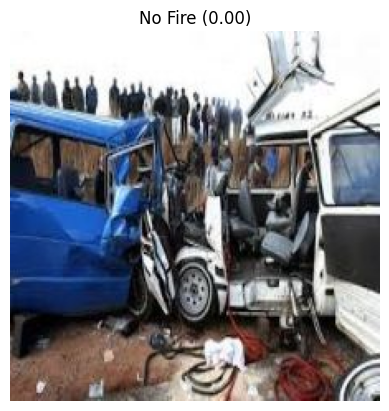

In [12]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# 테스트할 이미지 파일 이름 (업로드한 파일명 또는 드라이브 경로)
img_path = '/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/fire_dataset/Test/Non-Fire/crash40.jpg'  # 예: 'fire1.jpg', 또는 '/content/drive/MyDrive/test/fire1.jpg'

# 이미지 전처리
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0
img_tensor = np.expand_dims(img_array, axis=0)

# 예측
prediction = model.predict(img_tensor)
prob = prediction[0][0]
label = 'Fire' if prob > 0.5 else 'No Fire'

# 출력
plt.imshow(img)
plt.title(f'{label} ({prob:.2f})')
plt.axis('off')
plt.show()

In [13]:
import os
import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model

# --- 설정 ---
test_dir = '/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/fire_dataset/Test'
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# --- Fire/Non-Fire 라벨링 수동으로 설정 ---
def make_test_df(base_dir, label_str, label_num):
    file_list = os.listdir(os.path.join(base_dir, label_str))
    return pd.DataFrame({
        'filename': [os.path.join(label_str, fname) for fname in file_list],
        'label': label_num
    })

fire_df = make_test_df(test_dir, 'Fire', 1)
non_fire_df = make_test_df(test_dir, 'Non-Fire', 0)
test_df = pd.concat([fire_df, non_fire_df], ignore_index=True)

# --- 모델 로드 ---
model = load_model('fire_detection_model.keras')

# --- 데이터 제너레이터 ---
test_gen = ImageDataGenerator(rescale=1./255)

test_data = test_gen.flow_from_dataframe(
    dataframe=test_df,
    directory=test_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='raw',  # 숫자 라벨을 직접 사용
    shuffle=False
)

# --- 평가 ---
loss, accuracy = model.evaluate(test_data)
print(f"\n✅ 테스트 데이터 정확도 (Fire=1 기준): {accuracy * 100:.2f}%")

Found 2000 validated image filenames.
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - accuracy: 0.9357 - loss: 0.1657

✅ 테스트 데이터 정확도 (Fire=1 기준): 86.75%
